# Lab: collecting public data from an API — McDonald's ice-cream machines

**BADM 534 · Module 2 (Customer Data and Visualization)** · companion files: `fetch_mcbroken.py`, `build_panel.py`, `README.md`

[McBroken](https://mcbroken.com) is a hobby site by software engineer Rashiq Zahid that checks, every few minutes, whether each McDonald's ice-cream machine is working. It does this by trying to add a sundae to a cart through McDonald's own ordering API; if the item can't be added, the machine is marked broken. The website is a map drawn from one JSON file, `markers.json`, that anyone can download. That file is our "API".

## What you will learn
1. What an HTTP request is, and how to read a response (status code, headers, body).
2. How to turn nested JSON into a tidy table with pandas.
3. How to be a polite data collector (identify yourself, set a timeout, don't hammer the server).
4. Why a single snapshot is rarely enough, and how "git scraping" turns a live feed into a time series.
5. How to check code an AI assistant wrote for you against the things that usually go wrong.

> **If you are on a locked-down network** (some campus and corporate networks block hobby sites), the live call will fail. The code falls back to a public-domain hourly archive of the same file on GitHub. The notebook you are reading was executed on such a network, so you will see the fallback happen below.

In [1]:
import sys, json, pathlib
import pandas as pd
import matplotlib.pyplot as plt
import requests

LAB = pathlib.Path("fetch_mcbroken.py").resolve().parent   # folder with the lab scripts
sys.path.insert(0, str(LAB))
import fetch_mcbroken as mcb

pd.set_option("display.width", 140)
print("pandas", pd.__version__, "| requests", requests.__version__)

pandas 2.3.3 | requests 2.34.2


## 1. An HTTP request, by hand

A web API is just a URL that returns data instead of a web page. `requests.get()` sends the request; the response object tells you whether it worked (`status_code` 200), what came back (`headers`), and the body (`content`).

Three habits worth forming from day one:
- **Say who you are.** The `User-Agent` header identifies your program. Hobby sites get hammered by anonymous bots; a clear name and a contact is basic courtesy.
- **Always set a `timeout`.** Without one, a stalled server stalls your notebook forever.
- **Check the status code** before parsing anything. `raise_for_status()` turns a 404 or 500 into a Python error you can see.

`stats.json` is a small file (a league table of cities), so it is a good first call.

In [2]:
try:
    stats, meta = mcb.get_json(mcb.LIVE_STATS)
    print(json.dumps(meta, indent=1))
    print("overall share of checked machines reported broken:", stats["broken"], "%")
    pd.DataFrame(stats["cities"]).sort_values("broken", ascending=False).head(10)
except requests.RequestException as e:
    print("Live endpoint not reachable from this network ->", type(e).__name__)
    print("(On your own laptop this cell prints the response metadata and a table of the 30 listed cities.)")

Live endpoint not reachable from this network -> ProxyError
(On your own laptop this cell prints the response metadata and a table of the 30 listed cities.)


## 2. The main file: one record per restaurant

`markers.json` is a GeoJSON *FeatureCollection*: a list of `features`, each with a `geometry` (longitude, latitude) and a `properties` dictionary. It is about 10 MB, served gzip-compressed. Note two things in `get_json()`:
- it decompresses the body itself when the server sends gzip bytes without saying so (look for the magic bytes `1f 8b`);
- `load_markers("auto")` tries the live URL first and then the archive copy on GitHub, printing a warning for each failure. Fallbacks like this are what make a data-collection script usable by other people.

In [3]:
features, meta = mcb.load_markers("auto")
print(json.dumps(meta, indent=1))
print(f"{len(features):,} features")
print(json.dumps(features[0], indent=1))

[warn] https://mcbroken.com/markers.json: ProxyError: HTTPSConnectionPool(host='mcbroken.com', port=443): Max retries exceeded with url: /markers.json (Caused by ProxyError('Unable to connect to proxy', OSError('Tunnel connection failed: 403 Forbidden')))


{
 "url": "https://raw.githubusercontent.com/MrFlynn/mcbroken-archive/main/mcbroken.json",
 "status_code": 200,
 "fetched_at_utc": "2026-10-25T02:32:17+00:00",
 "bytes": 8963352,
 "content_type": "text/plain; charset=utf-8",
 "content_encoding": "gzip",
 "elapsed_s": 0.1,
 "source": "archive"
}
20,715 features
{
 "geometry": {
  "coordinates": [
   -80.448234,
   27.638297,
   0.0
  ],
  "type": "Point"
 },
 "properties": {
  "is_broken": false,
  "is_active": true,
  "dot": "working",
  "state": "FL",
  "city": "Vero Beach",
  "street": "5875 20th St",
  "country": "USA",
  "last_checked": "Checked 30 minutes ago"
 },
 "type": "Feature"
}


### From nested JSON to a table

Two ways to flatten it. `pd.json_normalize` does the generic job in one line; the lab's `flatten()` adds the things an analyst actually wants (a stable `store_id`, the check time as a timestamp, numeric lat/lon).

In [4]:
quick = pd.json_normalize(features)          # generic: columns like properties.city, geometry.coordinates
print(quick.columns.tolist())

df = mcb.flatten(features, meta["fetched_at_utc"])
df.head()

['type', 'geometry.coordinates', 'geometry.type', 'properties.is_broken', 'properties.is_active', 'properties.dot', 'properties.state', 'properties.city', 'properties.street', 'properties.country', 'properties.last_checked']


,store_id,country,state,city,street,lat,lon,is_broken,is_active,dot,last_checked_min,checked_at_utc
0,"USA|FL|Vero Beach|5875 20th St|27.6383,-80.4482",USA,FL,Vero Beach,5875 20th St,27.638297,-80.448234,False,True,working,30,2026-10-25 02:02:17+00:00
1,"USA|FL|Naples|6065 Pine Ridge Rd|26.2121,-81.73",USA,FL,Naples,6065 Pine Ridge Rd,26.212114,-81.730039,False,True,working,19,2026-10-25 02:13:17+00:00
2,"USA|CO|Northglenn|599 W 104th Ave|39.8858,-104...",USA,CO,Northglenn,599 W 104th Ave,39.885781,-104.994653,False,True,working,4,2026-10-25 02:28:17+00:00
3,"TW||高雄市|高雄市苓雅區建國一路306號1樓|22.633,120.3255",TW,None,高雄市,高雄市苓雅區建國一路306號1樓,22.632963,120.325455,False,True,working,8,2026-10-25 02:24:17+00:00
4,"JP||１５号鶴見店|神奈川県横浜市鶴見区鶴見中央５－８－２|35.5042,139.6775",JP,,１５号鶴見店,神奈川県横浜市鶴見区鶴見中央５－８－２,35.504237,139.677478,True,True,broken,39,2026-10-25 01:53:17+00:00


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20715 entries, 0 to 20714
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype              
---  ------            --------------  -----              
 0   store_id          20715 non-null  object             
 1   country           20715 non-null  object             
 2   state             12593 non-null  object             
 3   city              20715 non-null  object             
 4   street            20715 non-null  object             
 5   lat               20715 non-null  float64            
 6   lon               20715 non-null  float64            
 7   is_broken         20715 non-null  bool               
 8   is_active         20715 non-null  bool               
 9   dot               20715 non-null  object             
 10  last_checked_min  20715 non-null  int64              
 11  checked_at_utc    20715 non-null  datetime64[ns, UTC]
dtypes: bool(2), datetime64[ns, UTC](1), float64(2), int64(1), ob

## 3. First look

Each row is a store that McBroken re-checked in the last hour. `is_broken` is True when a sundae could not be added to the cart. (That is the measure: "the app refused the order", not a technician's report. Think about what else could trigger it: the store is closed, the item is sold out, an app outage.)

In [6]:
print(f"stores in snapshot: {len(df):,}")
print(f"countries: {df['country'].nunique()}")
print(f"share broken, all countries: {df['is_broken'].mean():.1%}")

by_country = (df.groupby("country")["is_broken"].agg(n_checked="size", n_broken="sum")
                .assign(share_broken=lambda d: d.n_broken / d.n_checked)
                .sort_values("n_checked", ascending=False))
by_country.head(12).round({"share_broken": 3})

stores in snapshot: 20,715
countries: 56
share broken, all countries: 11.7%


,n_checked,n_broken,share_broken
country,,,
USA,7556,882,0.117
JP,3026,365,0.121
UK,749,226,0.302
CA,748,27,0.036
IT,672,29,0.043
ES,659,15,0.023
PL,615,29,0.047
PH,428,7,0.016
ZA,403,60,0.149


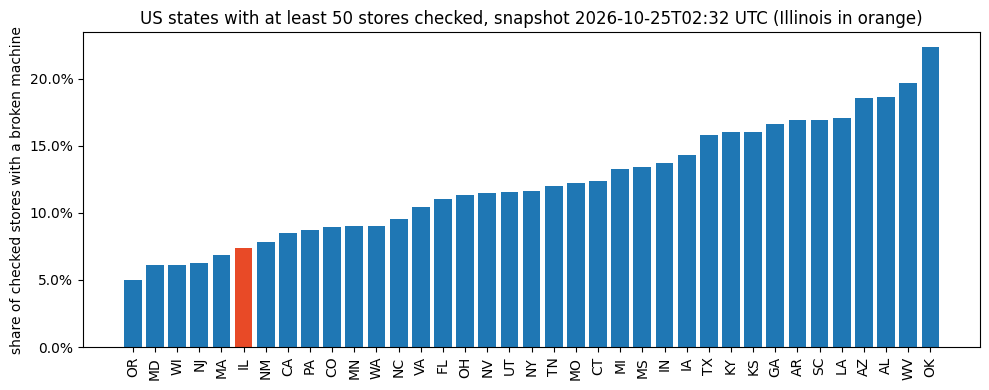

In [7]:
us = df[df["country"] == "USA"].copy()
by_state = (us.groupby("state")["is_broken"].agg(n_checked="size", n_broken="sum")
              .assign(share_broken=lambda d: d.n_broken / d.n_checked))
big = by_state[by_state.n_checked >= 50].sort_values("share_broken")

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(big.index, big.share_broken, color=["#1f77b4" if s != "IL" else "#E84A27" for s in big.index])
ax.set_ylabel("share of checked stores with a broken machine")
ax.set_title(f"US states with at least 50 stores checked, snapshot {meta['fetched_at_utc'][:16]} UTC (Illinois in orange)")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.xticks(rotation=90); plt.tight_layout()

## 4. A map without a mapping library

Longitude and latitude are just x and y. For a quick look that is all you need; `plotly.express.scatter_geo` or `folium` give you a real basemap later.

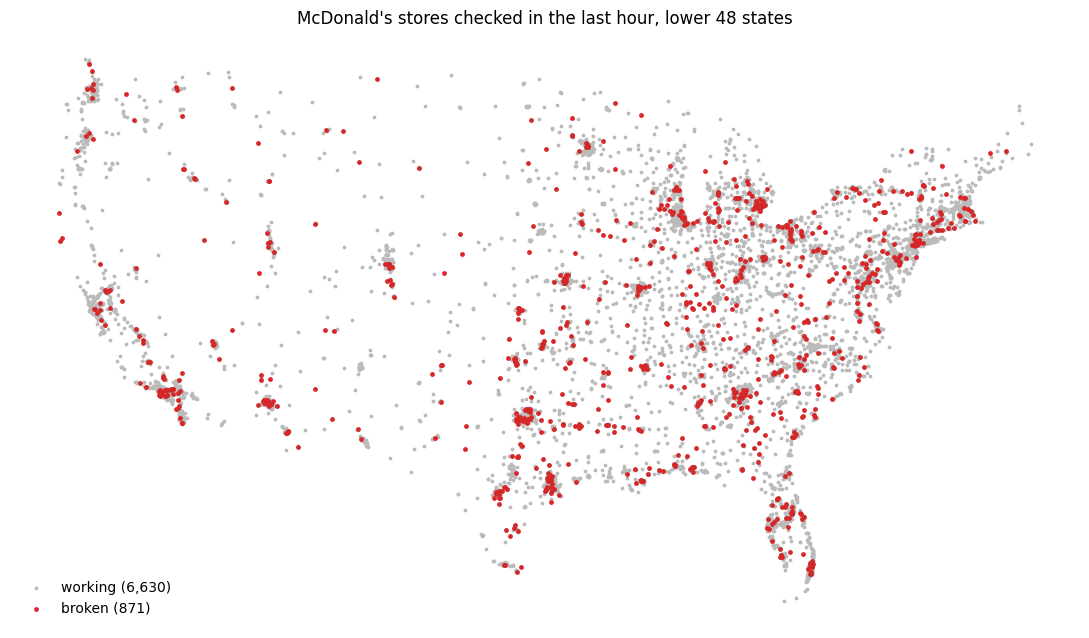

In [8]:
lower48 = us[(us.lon.between(-125, -66)) & (us.lat.between(24, 50))]
fig, ax = plt.subplots(figsize=(11, 6.5))
ok = lower48[~lower48.is_broken]; bad = lower48[lower48.is_broken]
ax.scatter(ok.lon, ok.lat, s=3, c="#bbbbbb", label=f"working ({len(ok):,})")
ax.scatter(bad.lon, bad.lat, s=6, c="#d62728", label=f"broken ({len(bad):,})")
ax.set_aspect(1.3); ax.axis("off"); ax.legend(loc="lower left", frameon=False)
ax.set_title("McDonald's stores checked in the last hour, lower 48 states")
plt.tight_layout()

## 5. From a snapshot to a time series ("git scraping")

The live file only describes *now*. To study anything over time you need to keep copies. Rather than run a server, the cheapest trick is to let GitHub do it: a scheduled GitHub Actions job downloads the file and commits it, so **the git history becomes the dataset**. Simon Willison named this pattern [git scraping](https://simonwillison.net/2020/Oct/9/git-scraping/). [MrFlynn/mcbroken-archive](https://github.com/MrFlynn/mcbroken-archive) has done exactly this for McBroken since October 2020 (60,000+ commits), and `build_panel.py` walks that history to produce the CSVs in `data/`.

Here we use the pre-built files: a daily US series for the past year, and a weekly series for six years.

days with fewer than 2,000 US stores checked (dropped as failed snapshots): 3
353 daily snapshots, 2025-10-25 to 2026-10-24; median US share 13.2%


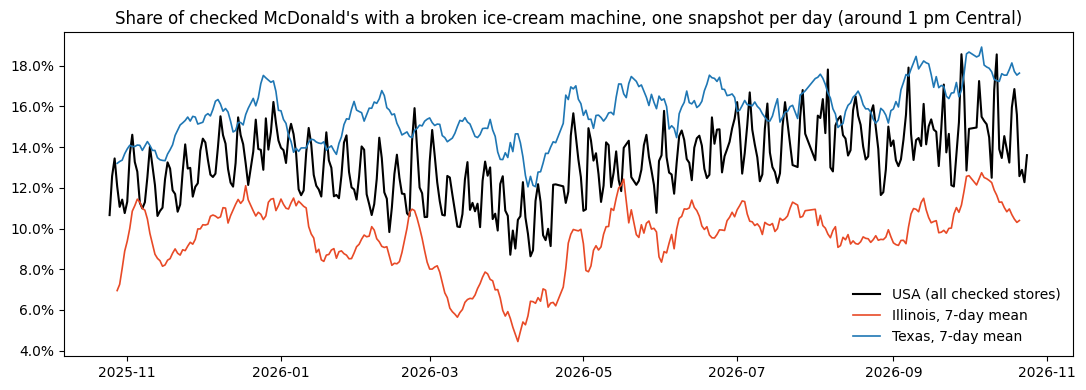

In [9]:
DATA = LAB / "data"
daily = pd.read_csv(sorted(DATA.glob("mcbroken_daily_*_us_state.csv"))[-1], parse_dates=["date"])
weekly = pd.read_csv(sorted(DATA.glob("mcbroken_weekly_*_country.csv"))[-1], parse_dates=["date"])

nat = daily.groupby("date")[["n_checked", "n_broken"]].sum()
print(f"days with fewer than 2,000 US stores checked (dropped as failed snapshots): {(nat.n_checked < 2000).sum()}")
nat = nat[nat.n_checked >= 2000]
nat["share_broken"] = nat.n_broken / nat.n_checked
ok_days = daily[daily.n_checked >= 50]                      # a state needs a decent denominator on that day
il = ok_days[ok_days.state == "IL"].set_index("date")["share_broken"]
tx = ok_days[ok_days.state == "TX"].set_index("date")["share_broken"]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(nat.index, nat.share_broken, color="black", lw=1.5, label="USA (all checked stores)")
ax.plot(il.index, il.rolling(7, center=True).mean(), color="#E84A27", lw=1.2, label="Illinois, 7-day mean")
ax.plot(tx.index, tx.rolling(7, center=True).mean(), color="#1f77b4", lw=1.2, label="Texas, 7-day mean")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("Share of checked McDonald's with a broken ice-cream machine, one snapshot per day (around 1 pm Central)")
ax.legend(frameon=False); plt.tight_layout()
print(f"{len(nat)} daily snapshots, {nat.index.min():%Y-%m-%d} to {nat.index.max():%Y-%m-%d}; median US share {nat.share_broken.median():.1%}")

299 weekly snapshots; share broken: first year median 10.1%, last year median 14.5%


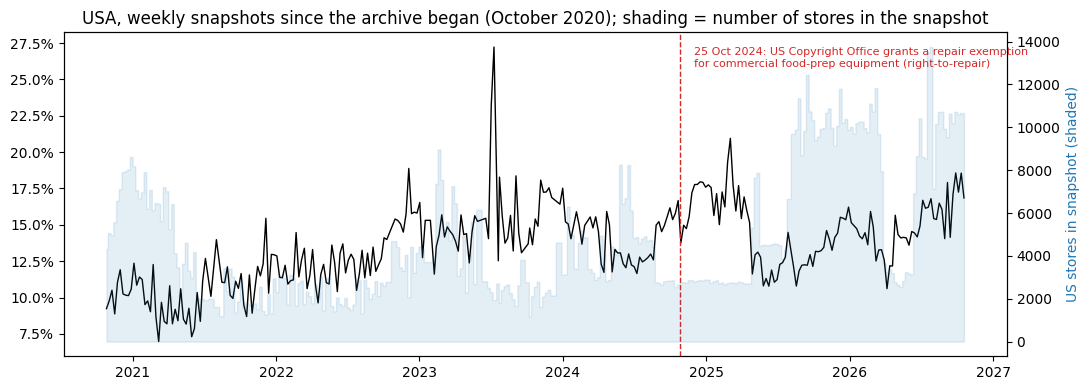

In [10]:
w = weekly[(weekly.country == "USA") & (weekly.n_checked >= 1000)].set_index("date")
w_us = w["share_broken"]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(w_us.index, w_us, color="black", lw=1)
ax2 = ax.twinx()
ax2.fill_between(w.index, w.n_checked, color="#1f77b4", alpha=0.12, step="mid")
ax2.set_ylabel("US stores in snapshot (shaded)", color="#1f77b4")
ax.axvline(pd.Timestamp("2024-10-25"), color="#d62728", ls="--", lw=1)
ax.annotate("25 Oct 2024: US Copyright Office grants a repair exemption\nfor commercial food-prep equipment (right-to-repair)",
            xy=(pd.Timestamp("2024-10-25"), w_us.max() * 0.95), xytext=(10, 0), textcoords="offset points", fontsize=8, color="#d62728")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("USA, weekly snapshots since the archive began (October 2020); shading = number of stores in the snapshot")
plt.tight_layout()
print(f"{len(w_us)} weekly snapshots; share broken: first year median {w_us[:'2021-10'].median():.1%}, last year median {w_us['2025-10':].median():.1%}")

**A note before anyone fits a model.** The denominator is "stores McBroken happened to re-check in that hour", which changes over time (the shaded area; the archive's own filter and McBroken's checking cadence have both changed). Level shifts that line up with jumps in the shading are measurement changes, not McFlurry events. Scraped data is like that; the first job is always to understand how the numbers were made. See the README for the data dictionary and known issues.

The dashed line marks a natural event for Module 6: on 25 October 2024 the US Copyright Office granted a DMCA exemption allowing third parties to repair commercial food-preparation equipment, after a petition by iFixit and Public Knowledge. Did outage rates fall afterwards, relative to countries where nothing changed? That is a difference-in-differences question, and `mcbroken_weekly_*_country.csv` has the comparison countries.

## 6. A documented API, for contrast: GitHub's REST API

McBroken's file is an *undocumented* endpoint: no parameters, no key, no guarantees. Most APIs you will meet at work are documented and parameterised. GitHub's REST API is a good, free example, and here it answers a real question: when were the archive's recent snapshots taken? Notice the query parameters in the URL, the JSON structure, and the rate-limit headers (60 requests an hour without a token).

In [11]:
url = "https://api.github.com/repos/MrFlynn/mcbroken-archive/commits"
r = requests.get(url, params={"per_page": 8, "path": "mcbroken.json"},
                 headers={"User-Agent": mcb.USER_AGENT, "Accept": "application/vnd.github+json"}, timeout=30)
print(r.status_code, r.url)
print("rate limit remaining:", r.headers.get("X-RateLimit-Remaining"), "of", r.headers.get("X-RateLimit-Limit"))
if r.ok:
    commits = pd.DataFrame([{"sha": c["sha"][:10], "when_utc": c["commit"]["committer"]["date"], "message": c["commit"]["message"]} for c in r.json()])
    display(commits)
else:
    print(r.text[:300])

200 https://api.github.com/repos/MrFlynn/mcbroken-archive/commits?per_page=8&path=mcbroken.json
rate limit remaining: 59 of 60


,sha,when_utc,message
0,e1540bea83,2026-10-24T23:39:24Z,Archive from Sat Oct 24 23:39:24 UTC 2026
1,bf26e74b95,2026-10-24T21:08:09Z,Archive from Sat Oct 24 21:08:09 UTC 2026
2,0f243da3f2,2026-10-24T18:19:57Z,Archive from Sat Oct 24 18:19:57 UTC 2026
3,a07a7e0373,2026-10-24T14:49:45Z,Archive from Sat Oct 24 14:49:45 UTC 2026
4,631bc56562,2026-10-24T11:32:26Z,Archive from Sat Oct 24 11:32:26 UTC 2026
5,b7be944f60,2026-10-24T06:24:08Z,Archive from Sat Oct 24 06:24:08 UTC 2026
6,e0877c96cd,2026-10-24T01:02:18Z,Archive from Sat Oct 24 01:02:18 UTC 2026
7,612b707f1e,2026-10-23T22:35:07Z,Archive from Fri Oct 23 22:35:07 UTC 2026


## 7. Exercises

1. **Audit the AI.** Ask your coding assistant to "write a Python function that downloads https://mcbroken.com/markers.json and returns a pandas DataFrame". Then check its answer against this list: Does it set a timeout? Does it send a User-Agent? Does it check the status code? What happens if the body is gzip without a header? Does it keep a raw copy? Fix what is missing, and keep the prompt-and-fix pair for your lab write-up.
2. **Normalise.** Join the state table to population (the Census Bureau's API, `https://api.census.gov/data/`, is documented and free) and ask whether "broken machines per million residents" tells a different story than the share.
3. **Within-day pattern.** The archive has several snapshots a day. Modify `build_panel.py` to keep every commit for one week and plot the share broken by hour of day. When are machines most often "broken"? What does that suggest about what the measure captures?
4. **Store persistence.** Join `mcbroken_daily_*_stores_us_panel.csv.gz` to `*_stores_us_dim.csv` on `store_key` and compute, for each store seen on at least 30 days, the share of days it was broken. Is it a few chronic stores or many occasional ones? Plot the distribution, then map the worst 2%.
5. **Event study (Module 6 preview).** Using the weekly country file, compare the US with Canada and the UK before and after 25 October 2024. Write down the identifying assumption before you look at the plot.
6. **Your own archive.** Copy `snapshot_mcbroken.yml` into a GitHub repository of your own and let it run for the rest of the term.